# **Notebook 4 - Analyzing and Scaling Models**

In this notebook, **you'll look at two things that matter once models get larger or harder**: how to build large problems efficiently, and how to analyze the functions of a model directly in Python — evaluating values, gradients and Hessians, bounding them over boxes with interval arithmetic, checking convexity numerically, and constructing αBB underestimators.

## Table of Contents
0. [Setup](#0-setup)
1. [Building Large Problems Efficiently](#1-building-large-problems-efficiently)
2. [Evaluating Functions](#2-evaluating-functions)
3. [Interval Evaluation](#3-interval-evaluation)
4. [Interval Derivatives and a Numerical Convexity Check](#4-interval-derivatives-and-a-numerical-convexity-check)
5. [αBB Underestimators](#5-αbb-underestimators)
6. [Notebook 4 - Key Takeaways](#6-key-takeaways)

## **0. Setup**

First, install SHOTpy and matplotlib, then import the modules.

In [1]:
%pip install SHOTpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import time

import matplotlib.pyplot as plt

import SHOTpy

## **1. Building Large Problems Efficiently**

The earlier notebooks add variables, constraints and terms one at a time, which reads well and is fine for small models. However, for large models it does not scale. To build a large problem efficiently, define a Pyhton list and use the following commands:

| Instead of | Use |
| --- | --- |
| `problem.addVariable(v)` in a loop | `problem.addVariables(list_of_variables)` |
| `problem.addConstraint(c)` in a loop | `problem.addConstraints(list_of_constraints)` |
| `problem.addConstraint(x <= 1, name)` in a loop | `problem.addConstraints(list_of_comparisons, list_of_names)` |
| `constraint.add(LinearTerm(c, v))` in a loop | `constraint.add(SHOTpy.LinearTerms(coefficients, variables))` |
| `constraint.add(QuadraticTerm(c, u, v))` in a loop | `constraint.add(SHOTpy.QuadraticTerms(coefficients, first, second))` |

The bulk add merges the terms through a hash map in a single pass, so the result is exactly the same as adding them one at a time — only faster. 

The example below builds a linear and a quadratic constraint with $N = 20\,000$ terms each, first one term at a time and then all terms at once:

In [11]:
N = 20000

def build(bulk):
    """Build one linear row and one quadratic row of N terms, returning the time it took."""
    solver = SHOTpy.Solver()
    problem = SHOTpy.Problem(solver)

    variables = [SHOTpy.Variable(f"x{i}", SHOTpy.VariableType.Real, 0.0, 10.0) for i in range(N)]
    coefficients = [1.0 + i for i in range(N)]

    # A list is accepted wherever a Variables container is
    problem.addVariables(variables)

    start = time.perf_counter()

    row = SHOTpy.LinearConstraint("row", 0.0, 1.0)
    quadratic_row = SHOTpy.QuadraticConstraint("qrow", SHOTpy.SHOT_DBL_MIN, 1.0)

    if bulk:
        row.add(SHOTpy.LinearTerms(coefficients, variables))
        quadratic_row.add(SHOTpy.QuadraticTerms(coefficients, variables, variables))
    else:
        for c, v in zip(coefficients, variables):
            row.add(SHOTpy.LinearTerm(c, v))
        for c, v in zip(coefficients, variables):
            quadratic_row.add(SHOTpy.QuadraticTerm(c, v, v))

    elapsed = time.perf_counter() - start

    problem.addConstraints([row, quadratic_row])
    return elapsed, problem

single_time, single_problem = build(bulk=False)
bulk_time, bulk_problem = build(bulk=True)

print(f"one term at a time : {single_time:7.3f} s")
print(f"all terms at once  : {bulk_time:7.3f} s  ({single_time / bulk_time:.0f} times faster)")
print("the two problems are identical:", single_problem.toString() == bulk_problem.toString())

one term at a time :   0.150 s
all terms at once  :   0.004 s  (39 times faster)
the two problems are identical: True


### Other Ways of Building a Container

A container can also be built from a list of terms, built up with `append` (which does not merge terms of the same variable, and `reserve` takes the number of terms that will be added), or handed a list directly: `constraint.add([...])` converts the list and adds all of it at once. Constraints written as comparisons are added all at once with `problem.addConstraints(comparisons, names)`.

In [12]:
# Create solver
solver = SHOTpy.Solver()

# Create problem
problem = SHOTpy.Problem(solver)

# Add variables, all at once
x = SHOTpy.Variable("x", SHOTpy.VariableType.Real, 0.0, 10.0)
y = SHOTpy.Variable("y", SHOTpy.VariableType.Real, 0.0, 10.0)
problem.addVariables([x, y])

# Set objective: 2x + 3y, from a list of terms
objective = SHOTpy.LinearObjectiveFunction(SHOTpy.ObjectiveDirection.Minimize)
objective.add(SHOTpy.LinearTerms([SHOTpy.LinearTerm(2.0, x), SHOTpy.LinearTerm(3.0, y)]))
problem.setObjective(objective)

# Add constraints
# x + y >= 1, from terms built up with append
terms = SHOTpy.LinearTerms()
terms.reserve(2)
terms.append(SHOTpy.LinearTerm(1.0, x))
terms.append(SHOTpy.LinearTerm(1.0, y))
c1 = SHOTpy.LinearConstraint("c1", 1.0, SHOTpy.SHOT_DBL_MAX)
c1.add(terms)

# x - y <= 3, from a list passed straight to add()
c2 = SHOTpy.LinearConstraint("c2", SHOTpy.SHOT_DBL_MIN, 3.0)
c2.add([SHOTpy.LinearTerm(1.0, x), SHOTpy.LinearTerm(-1.0, y)])

problem.addConstraints([c1, c2])

# Comparisons and their names, all at once
problem.addConstraints([x + 2*y <= 15, 2*x + y <= 15], ["c3", "c4"])

# Finalize problem
problem.finalize()
print(problem.toString())

minimize:
[L-convex    ] [L    ]	  +2*x +3*y

subject to:
[    0,L-convex    ] [L    ]           c1:  -x -y <= -1
[    1,L-convex    ] [L    ]           c2:  +x -y <= 3
[    2,L-convex    ] [L    ]           c3:  +x +2*y <= 15
[    3,L-convex    ] [L    ]           c4:  +2*x +y <= 15

variables:
[     0,C ] [OL  ] [L       ]	    0.000000    <=        x          <=   10.000000   
[     1,C ] [OL  ] [L       ]	    0.000000    <=        y          <=   10.000000   

Problem is convex.



## **2. Evaluating Functions**

The objective function and the constraints can be evaluated at a point, which is a list with a value for each variable in the order of their indexes:

| Method | Returns |
|---|---|
| `objectiveFunction.calculateValue(point)` | the value of the objective function, including its constant |
| `constraint.calculateFunctionValue(point)` | $f(x)$ of the constraint $L \le f(x) \le U$ |
| `constraint.calculateNumericValue(point)` | a `NumericConstraintValue` with `functionValue`, `isFulfilled`, `error` and the deviations from $L$ and $U$ |
| `constraint.isFulfilled(point)` | whether $L \le f(x) \le U$ |
| `calculateGradient(point)` / `calculateHessian(point)` | the nonzeros as `{index: value}` / `{(index1, index2): value}` |
| `expression.calculate(point)` | the value of an expression, also one that is not in a constraint |
| `problem.getMostDeviatingNumericConstraint(point)` | the `NumericConstraintValue` of the most violated constraint, or `None` |

A point without a value for every variable raises a `ValueError`. The Hessian is symmetric, so `calculateHessian` only returns the upper triangle, *i.e.*, the elements with `index1 <= index2`; the example below mirrors them into the full matrix.

Since `finalize()` can replace or rewrite the constraints and the objective (see Notebook 1), they are read back from the problem before they are evaluated.

In [14]:
# Create problem
problem = SHOTpy.Problem(solver)

# Add variables
x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.0, 10.0)
y = problem.addVariable("y", SHOTpy.VariableType.Real, 0.1, 10.0)

# Set objective: x^2 - y + 4
problem.setObjective(x**2 - y + 4, SHOTpy.ObjectiveDirection.Minimize)

# Add constraints
problem.addConstraint(SHOTpy.inequality(1, x + 2*y, 8), "lin")         # 1 <= x + 2y <= 8
problem.addConstraint(SHOTpy.exp(x) + SHOTpy.log(y) <= 5, "nl")         # exp(x) + log(y) <= 5

# Finalize problem
problem.finalize()

# Read the constraints and the objective back from the problem
constraints = {c.name: c for c in problem.numericConstraints}
objective = problem.objectiveFunction

# Evaluate at the point x = 2, y = 1
point = [2.0, 1.0]
print(f"Objective value   : {objective.calculateValue(point):.4f}")
print(f"Objective gradient: {objective.calculateGradient(point)}")
print(f"Objective Hessian : {objective.calculateHessian(point)}")

for name, constraint in constraints.items():
    value = constraint.calculateNumericValue(point)
    print(f"{name}: f(x) = {value.functionValue:.4f}, fulfilled = {value.isFulfilled}, "
          f"error = {value.error:.4f}, gradient = {constraint.calculateGradient(point)}")

worst = problem.getMostDeviatingNumericConstraint(point)
print(f"Most violated constraint: {worst.constraint.name if worst else None}")

# The Hessian only has the upper triangle, so it is mirrored to get the full matrix
hessian = constraints["nl"].calculateHessian(point)
print(f"Hessian of nl     : {hessian}")

matrix = [[0.0] * len(point) for _ in point]
for (i, j), value in hessian.items():
    matrix[i][j] = matrix[j][i] = value
print(f"As a full matrix  : {matrix}")

# An expression can be evaluated directly, without adding it to a constraint
print(f"x*y + exp(x)      : {(x*y + SHOTpy.exp(x)).calculate(point):.4f}")

Objective value   : 7.0000
Objective gradient: {0: 4.0, 1: -1.0}
Objective Hessian : {(0, 0): 2.0}
lin: f(x) = 4.0000, fulfilled = True, error = 0.0000, gradient = {0: 1.0, 1: 2.0}
nl: f(x) = 7.3891, fulfilled = False, error = 2.3891, gradient = {0: 7.38905609893065, 1: 1.0}
Most violated constraint: nl
Hessian of nl     : {(0, 0): 7.38905609893065, (1, 1): -1.0}
As a full matrix  : [[7.38905609893065, 0.0], [0.0, -1.0]]
x*y + exp(x)      : 9.3891


## **3. Interval Evaluation**

The functions can also be bounded over a box, which is a list with an `SHOTpy.Interval` for each variable. A tuple `(lower, upper)` or a number can be used in place of an `Interval`:

| Method | Returns |
|---|---|
| `objectiveFunction.calculateValue(box)` / `objectiveFunction.getBounds()` | the bounds over the box / over the variable bounds |
| `constraint.calculateFunctionValue(box)` / `constraint.getConstraintFunctionBounds()` | the bounds of $f(x)$ over the box / over the variable bounds |
| `expression.calculate(box)` / `expression.getBounds()` | the bounds of an expression over the box / over the variable bounds |
| `problem.getVariableBounds()` / `variable.getBound()` | the variable bounds as `Interval`s |

The bounds are calculated with interval arithmetic, so they contain all the values of the function in the box, but are often wider than the range of the values. The arguments of functions such as `log` and `sqrt` are restricted to their domains. The bounds of a constraint or the objective function are `[SHOT_DBL_MIN, SHOT_DBL_MAX]` if they cannot be calculated, while an expression raises `SHOTpy.IntervalError`. The bounds are not rounded outwards, so they are not verified enclosures of the floating-point calculations.

The example uses the problem from Section 2:

In [ ]:
box = [(1.0, 3.0), SHOTpy.Interval(0.5, 2.0)] # x in [1, 3], y in [0.5, 2]

print(f"Objective bounds over the box   : {objective.calculateValue(box)}")
print(f"Objective bounds over the bounds: {objective.getBounds()}")

for name, constraint in constraints.items():
    print(f"{name}: f(x) in {constraint.calculateFunctionValue(box)} over the box")

# An Interval supports arithmetic and can be unpacked
bounds = (x*y + SHOTpy.exp(x)).calculate(box)
lower, upper = bounds
print(f"x*y + exp(x) in [{lower:.4f}, {upper:.4f}], width {bounds.width:.4f}, contains 10: {10 in bounds}")
print(f"Twice the bounds: {2 * bounds}")

# log(y - 5) is not defined anywhere in the box, since y <= 2 there
try:
    SHOTpy.log(y - 5).calculate(box)
except SHOTpy.IntervalError as error:
    print(f"IntervalError: {error}")

Objective bounds over the box   : Interval(3.0, 12.5)
Objective bounds over the bounds: Interval(-6.0, 103.9)
lin: f(x) in Interval(2.0, 7.0) over the box
nl: f(x) in Interval(2.0251346478990997, 20.77868410374761) over the box
x*y + exp(x) in [3.2183, 26.0855], width 22.8673, contains 10: True
Twice the bounds: Interval(6.43656365691809, 52.171073846375336)
IntervalError: The expression is not defined anywhere in the box.


## **4. Interval Derivatives and a Numerical Convexity Check**

`calculateIntervalDerivatives(box, order=2)` of a constraint, the objective function or an expression returns an `IntervalDerivatives` with bounds over the box of the value (`value`), the gradient (`gradient`, `{index: Interval}`) and the upper triangle of the Hessian (`hessian`, `{(index1, index2): Interval}`). The bounds only enclose the derivatives when the function is defined everywhere in the box (`isDefinedOnBox`) and continuously differentiable up to the order of the derivative (`differentiableOrder`); `isBounded` tells whether all the bounds are finite.

A twice continuously differentiable function is convex on a box if its Hessian is positive semidefinite everywhere in it. The interval Hessian contains all the Hessians in the box, so by Gershgorin's theorem it is enough that each diagonal element is at least the sum of the absolute values of the other elements of its row:

$$
\operatorname{lower}(H_{ii}) - \sum_{j\ne i}\max\!\left(\left|\operatorname{lower}(H_{ij})\right|,\left|\operatorname{upper}(H_{ij})\right|\right) \ge 0 \quad \text{for every }i.
$$

The bounds are not rounded outwards, so this is a numerical check, not a proof: a verified certificate needs outward rounding both in SHOT's interval arithmetic and in the sums of the check.

In [16]:
def check_convexity(derivatives, number_of_variables):
    """True if the function passes the convexity check on the box, False if it does not, which is inconclusive, and
    None if the bounds cannot be used, e.g., since the function is not twice continuously differentiable there."""
    if not (derivatives.isDefinedOnBox and derivatives.differentiableOrder == 2 and derivatives.isBounded):
        return None

    hessian = derivatives.hessian

    for i in range(number_of_variables):
        diagonal = hessian[(i, i)].lower if (i, i) in hessian else 0.0
        others = sum(max(abs(h.lower), abs(h.upper)) for (j, k), h in hessian.items() if (j == i) != (k == i))

        if diagonal - others < 0.0:
            return False

    return True

# x*y is not convex, so SHOT classifies exp(x) + exp(y) + x*y as nonconvex, which it is on, e.g., [-5, -4]^2.
# On [1, 2]^2, however, the diagonal of the Hessian [[exp(x), 1], [1, exp(y)]] is at least e > 1.
function = SHOTpy.exp(x) + SHOTpy.exp(y) + x*y
derivatives = function.calculateIntervalDerivatives([(1, 2), (1, 2)])
print(derivatives)
print(f"Gradient: {derivatives.gradient}")
print(f"Hessian : {derivatives.hessian}")
print(f"Convex on [1, 2]^2  : {check_convexity(derivatives, 2)}")
print(f"Convex on [-5, -4]^2: {check_convexity(function.calculateIntervalDerivatives([(-5, -4), (-5, -4)]), 2)}")

<IntervalDerivatives: value Interval(6.43656365691809, 18.7781121978613), isDefinedOnBox True, differentiableOrder 2, isBounded True>
Gradient: {0: Interval(3.718281828459045, 9.38905609893065), 1: Interval(3.718281828459045, 9.38905609893065)}
Hessian : {(0, 0): Interval(2.718281828459045, 7.38905609893065), (0, 1): Interval(1.0, 1.0), (1, 1): Interval(2.718281828459045, 7.38905609893065)}
Convex on [1, 2]^2  : True
Convex on [-5, -4]^2: False


In [18]:
# x^3 + y^2 is convex where x >= 0. Splitting the box shows where the check passes
function = x**3 + y**2

for k in range(6):
    box = [(-1.0 + 0.5 * k, -0.5 + 0.5 * k), (-1.0, 1.0)]
    print(f"x in [{box[0][0]:4.1f}, {box[0][1]:4.1f}]: {check_convexity(function.calculateIntervalDerivatives(box), 2)}")

# |x| + y^2 is convex, but not twice differentiable at x = 0, so the bounds cannot be used there
derivatives = (SHOTpy.abs(x) + y**2).calculateIntervalDerivatives([(-1, 1), (-1, 1)])
print(f"|x| + y^2: differentiable order {derivatives.differentiableOrder}, check {check_convexity(derivatives, 2)}")

x in [-1.0, -0.5]: False
x in [-0.5,  0.0]: False
x in [ 0.0,  0.5]: True
x in [ 0.5,  1.0]: True
x in [ 1.0,  1.5]: True
x in [ 1.5,  2.0]: True
|x| + y^2: differentiable order 0, check None


In [19]:
# A failed check is inconclusive, since the bounds can be wider than the Hessians. A point in the interior of the box
# where the Hessian has a negative eigenvalue shows that the function is not convex on the box.
def eigenvalues(hessian):
    """The eigenvalues of a symmetric 2x2 matrix given by its upper triangle."""
    a, b, c = hessian.get((0, 0), 0.0), hessian.get((0, 1), 0.0), hessian.get((1, 1), 0.0)
    radius = math.sqrt(((a - c) / 2) ** 2 + b**2)
    return ((a + c) / 2 - radius, (a + c) / 2 + radius)

# A problem with the bilinear constraint u*v <= 0.5
bilinear_problem = SHOTpy.Problem(solver)
u = bilinear_problem.addVariable("u", SHOTpy.VariableType.Real, -1.0, 1.0)
v = bilinear_problem.addVariable("v", SHOTpy.VariableType.Real, -1.0, 1.0)
bilinear_problem.addConstraint(u*v <= 0.5, "bilinear")
bilinear_problem.setObjective(u + v, SHOTpy.ObjectiveDirection.Minimize)
bilinear_problem.finalize()

bilinear = bilinear_problem.getConstraint("bilinear")
print(f"Check on [-1, 1]^2         : {check_convexity(bilinear.calculateIntervalDerivatives([(-1, 1), (-1, 1)]), 2)}")
print(f"Eigenvalues at (0.2, -0.3): {eigenvalues(bilinear.calculateHessian([0.2, -0.3]))}")

Check on [-1, 1]^2         : False
Eigenvalues at (0.2, -0.3): (-1.0, 1.0)


## **5. αBB Underestimators**

The interval Hessian also gives a convex underestimator of a nonconvex function on a box, as in the αBB method. For a twice continuously differentiable $f$ on the box $[l, u]$,

$$
L(x) = f(x) + \alpha \sum_i (x_i-l_i)(x_i-u_i)
$$

is below $f$ on the box, since each added term is at most zero, and equal to $f$ at the corners of the box. Its Hessian is that of $f$ plus $2\alpha I$, so $L$ is convex if $2\alpha$ is at least minus the smallest eigenvalue of the Hessian anywhere in the box. The Gershgorin bound of the convexity check gives a lower bound on that eigenvalue:

$$
\alpha = \max\!\left(0,-\frac12\min_i\left[\operatorname{lower}(H_{ii})-\sum_{j\ne i}\max\!\left(\left|\operatorname{lower}(H_{ij})\right|,\left|\operatorname{upper}(H_{ij})\right|\right)\right]\right).
$$

For a function of one variable, this is $\alpha=\max(0,-\tfrac12\operatorname{lower}(f^{\prime\prime}))$. The largest gap between $f$ and $L$ is $\alpha(u-l)^2/4$, in the middle of the interval, so it shrinks quadratically when the box is split, which is what a branch-and-bound method using αBB relies on. As for the convexity check, the bounds are not rounded outwards, so $L$ is only numerically an underestimator.

The example below constructs the underestimator of the nonconvex $f(t) = \sin(3t) + t^2/4$ on $[-2, 2]$, and on the two halves $[-2, 0]$ and $[0, 2]$:

[-2.0,  2.0]: alpha = 4.2500, largest gap 17.0000 (alpha (u - l)^2 / 4 = 17.0000)
Underestimator on [-2, 2]: largest gap 17.0000
[-2.0,  0.0]: alpha = 4.2500, largest gap 4.2500 (alpha (u - l)^2 / 4 = 4.2500)
[ 0.0,  2.0]: alpha = 4.2500, largest gap 4.2500 (alpha (u - l)^2 / 4 = 4.2500)
Underestimator on [-2, 0] and [0, 2]: largest gap 4.2500


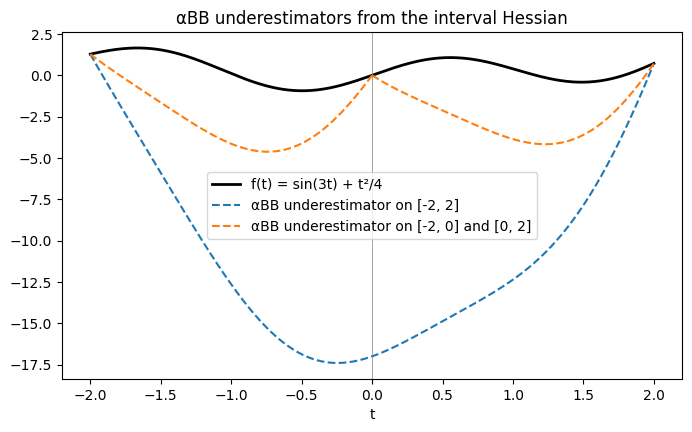

In [20]:
def alpha_bb(derivatives, number_of_variables):
    """The alpha of the alphaBB underestimator from the Gershgorin bound of the interval Hessian."""
    assert derivatives.isDefinedOnBox and derivatives.differentiableOrder == 2 and derivatives.isBounded
    hessian = derivatives.hessian
    smallest = min((hessian[(i, i)].lower if (i, i) in hessian else 0.0)
                   - sum(max(abs(h.lower), abs(h.upper)) for (j, k), h in hessian.items() if (j == i) != (k == i))
                   for i in range(number_of_variables))
    return max(0.0, -0.5 * smallest)

abb_problem = SHOTpy.Problem(solver)
t = abb_problem.addVariable("t", SHOTpy.VariableType.Real, -2.0, 2.0)
f = SHOTpy.sin(3*t) + 0.25*t**2   # nonconvex: f''(t) = -9 sin(3t) + 0.5

def underestimator(lower, upper):
    """alpha and L(t) = f(t) + alpha (t - lower)(t - upper) on [lower, upper]."""
    alpha = alpha_bb(f.calculateIntervalDerivatives([(lower, upper)]), 1)
    return alpha, (lambda value: f.calculate([value]) + alpha * (value - lower) * (value - upper))

pieces = {"[-2, 2]": [(-2.0, 2.0)], "[-2, 0] and [0, 2]": [(-2.0, 0.0), (0.0, 2.0)]}
points = [-2.0 + 4.0 * k / 400 for k in range(401)]

for name, boxes in pieces.items():
    largest_gap = 0.0
    for lower, upper in boxes:
        alpha, L = underestimator(lower, upper)
        inside = [p for p in points if lower <= p <= upper]
        gaps = [f.calculate([p]) - L(p) for p in inside]
        assert min(gaps) >= -1e-12                                    # L is below f
        assert abs(L(lower) - f.calculate([lower])) < 1e-12          # and equal to f at the ends
        largest_gap = max(largest_gap, max(gaps))
        print(f"[{lower:4.1f}, {upper:4.1f}]: alpha = {alpha:.4f}, largest gap {max(gaps):.4f}"
              f" (alpha (u - l)^2 / 4 = {alpha * (upper - lower) ** 2 / 4:.4f})")

    print(f"Underestimator on {name}: largest gap {largest_gap:.4f}")

# The underestimator on [-2, 2] passes the numerical convexity check
alpha, _ = underestimator(-2.0, 2.0)
convexified = f + alpha * (t + 2.0) * (t - 2.0)
assert check_convexity(convexified.calculateIntervalDerivatives([(-2.0, 2.0)]), 1)

# Plot f and the underestimators
figure, axes = plt.subplots(figsize=(8, 4.5))
axes.plot(points, [f.calculate([p]) for p in points], color="black", linewidth=2, label="f(t) = sin(3t) + t²/4")

for (name, boxes), color in zip(pieces.items(), ["tab:blue", "tab:orange"]):
    for number, (lower, upper) in enumerate(boxes):
        _, L = underestimator(lower, upper)
        inside = [p for p in points if lower <= p <= upper]
        axes.plot(inside, [L(p) for p in inside], color=color, linestyle="--",
                  label=f"αBB underestimator on {name}" if number == 0 else None)

axes.axvline(0.0, color="gray", linewidth=0.5)
axes.set_xlabel("t")
axes.set_title("αBB underestimators from the interval Hessian")
axes.legend()
plt.show()

## **6. Key Takeaways**

### 1. **Build Large Models in Bulk**
Adding one term or constraint at a time is fine for small models, but its cost grows with the number of terms. `addVariables`, `addConstraints`, `LinearTerms` and `QuadraticTerms` add everything at once and give exactly the same problem.

### 2. **Every Function of a Model Can Be Evaluated From Python**
Values, gradients and Hessians at a point, and the most violated constraint, are one call away — useful for checking a model, debugging a solution, or generating your own cuts in callbacks (Notebook 2).

### 3. **Interval Arithmetic Gives Bounds, Convexity Checks and Underestimators**
Bounding a function, its gradient and its Hessian over a box makes it possible to check convexity numerically and to construct αBB underestimators in a few lines of Python — a starting point for experimenting with your own algorithms around SHOT.

This concludes the SHOTpy tutorial.